<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/05_Espacios_Vectoriales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Modelos de espacios vectoriales</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">Matriz término-documento</span>](#matriz-termino-documento)
- [<span style="color: #005C99;">TF-IDF</span>](#tf-idf)
- [<span style="color: #005C99;">Similitud coseno y distancia euclidiana</span>](#similitud-coseno-y-distancia-euclidiana)
- [<span style="color: #005C99;">Un buscador de documentos</span>](#un-buscador-de-documentos)
- [<span style="color: #005C99;">Visualización con PCA</span>](#visualizacion-con-pca)
- [<span style="color: #005C99;">Vectores de palabras por co-ocurrencia</span>](#vectores-de-palabras-por-co-ocurrencia)
- [<span style="color: #005C99;">Hacia los embeddings</span>](#hacia-los-embeddings)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.decomposition import PCA, TruncatedSVD

SEED = 42
np.random.seed(SEED)

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

En los cuadernos anteriores cada palabra era un símbolo aislado: para el modelo, *bueno* y *excelente* eran tan distintas como *bueno* y *mesa*. Los **modelos de espacios vectoriales** representan documentos y palabras como **vectores** en un espacio donde la **geometría refleja el significado**: textos parecidos quedan cerca y textos distintos, lejos.

La idea se apoya en la **hipótesis distribucional** (Harris, 1954; Firth, 1957):

> *"Conocerás una palabra por la compañía que mantiene."*

Palabras que aparecen en contextos parecidos tienden a tener significados parecidos. Por ejemplo, de *"bebí un vaso de ___ frío"* podemos inferir que el hueco es una bebida sin haber visto nunca la palabra.

Los espacios vectoriales son la base de buscadores, sistemas de recomendación, detección de plagio, agrupamiento de documentos y, como veremos en el módulo 3, de los *word embeddings*.

<a id="matriz-termino-documento"></a>
<h2 style="color: #007ACC;">Matriz término-documento</h2>

La representación más directa es la **matriz término-documento**: cada fila es un documento, cada columna una palabra del vocabulario y cada celda cuántas veces aparece la palabra en el documento (el modelo de **bolsa de palabras**, *Bag-of-Words*).

In [3]:
documentos = [
    "el equipo ganó el partido de fútbol con un gol en el último minuto",
    "el delantero marcó un gol y el equipo celebró la victoria del partido",
    "el nuevo computador tiene un procesador rápido y mucha memoria",
    "instalé el programa en el computador y la memoria se llenó",
    "la receta lleva arroz pollo y verduras cocinadas a fuego lento",
    "cocinamos el pollo con arroz y una salsa de verduras",
]
temas = ["deporte", "deporte", "tecnología", "tecnología", "cocina", "cocina"]

vectorizador = CountVectorizer()
X_bow = vectorizador.fit_transform(documentos)
vocab = vectorizador.get_feature_names_out()

print(f"{X_bow.shape[0]} documentos x {X_bow.shape[1]} términos")
print(f"Celdas con valor cero: {1 - X_bow.nnz / np.prod(X_bow.shape):.0%} (matriz dispersa)")
pd.DataFrame(X_bow.toarray(), columns=vocab, index=[f"d{i} ({t})" for i, t in enumerate(temas)]).iloc[:, :18]

6 documentos x 40 términos
Celdas con valor cero: 75% (matriz dispersa)


,arroz,celebró,cocinadas,cocinamos,computador,con,de,del,delantero,el,en,equipo,fuego,fútbol,ganó,gol,instalé,la
d0 (deporte),0,0,0,0,0,1,1,0,0,3,1,1,0,1,1,1,0,0
d1 (deporte),0,1,0,0,0,0,0,1,1,2,0,1,0,0,0,1,0,1
d2 (tecnología),0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0
d3 (tecnología),0,0,0,0,1,0,0,0,0,2,1,0,0,0,0,0,1,1
d4 (cocina),1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
d5 (cocina),1,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,0,0


Observaciones:

- La matriz es **dispersa**: casi todas las celdas son cero. Con vocabularios reales (decenas de miles de palabras) siempre se almacena en formato disperso (`scipy.sparse`).
- Las palabras más frecuentes (*el*, *y*, *un*) aparecen en todos los documentos, así que no ayudan a distinguirlos. Sin embargo, pesan mucho en los conteos.

Ese segundo problema es el que resuelve TF-IDF.

<a id="tf-idf"></a>
<h2 style="color: #007ACC;">TF-IDF</h2>

**TF-IDF** (*term frequency – inverse document frequency*) pondera cada término según dos factores:

- **TF** (frecuencia del término): cuántas veces aparece el término $t$ en el documento $d$. Mientras más aparece, más representativo es del documento.
- **IDF** (frecuencia inversa de documento): qué tan raro es el término en la colección. Un término que aparece en todos los documentos no los distingue.

$$\text{tfidf}(t, d) = \text{tf}(t, d) \times \text{idf}(t), \qquad \text{idf}(t) = \log \frac{N}{\text{df}(t)}$$

donde $N$ es el número de documentos y $\text{df}(t)$ el número de documentos que contienen a $t$.

`scikit-learn` usa por defecto una versión **suavizada** que evita divisiones por cero y no anula del todo los términos que están en todos los documentos, y luego normaliza cada vector a longitud 1 (norma L2):

$$\text{idf}(t) = \ln \frac{1 + N}{1 + \text{df}(t)} + 1$$

Implementémoslo a mano y comparemos con `TfidfVectorizer`:

In [4]:
tf = X_bow.toarray().astype(float)
N = tf.shape[0]
df = (tf > 0).sum(axis=0)
idf = np.log((1 + N) / (1 + df)) + 1

tfidf_manual = tf * idf
tfidf_manual /= np.linalg.norm(tfidf_manual, axis=1, keepdims=True)  # normalización L2

tfidf_sk = TfidfVectorizer().fit_transform(documentos).toarray()
print("¿Coinciden la versión manual y la de scikit-learn?", np.allclose(tfidf_manual, tfidf_sk))

pd.DataFrame({"df": df, "idf": idf.round(3)}, index=vocab).sort_values("idf").iloc[[0, 1, 2, -3, -2, -1]]

¿Coinciden la versión manual y la de scikit-learn? True


,df,idf
el,5,1.154
la,3,1.560
un,3,1.560
una,1,2.253
victoria,1,2.253
último,1,2.253


*el* aparece en 5 de los 6 documentos y tiene el IDF más bajo; palabras como *delantero* o *receta* aparecen en uno solo y reciben el IDF más alto. Veamos los términos con mayor peso TF-IDF de cada documento:

In [5]:
for i, fila in enumerate(tfidf_sk):
    top = vocab[np.argsort(fila)[::-1][:4]]
    print(f"d{i} ({temas[i]:<10}): {', '.join(top)}")

d0 (deporte   ): el, último, minuto, ganó
d1 (deporte   ): el, victoria, marcó, delantero
d2 (tecnología): tiene, nuevo, procesador, rápido
d3 (tecnología): el, se, programa, llenó
d4 (cocina    ): fuego, lento, lleva, cocinadas
d5 (cocina    ): una, salsa, cocinamos, verduras


Aunque *el* tiene el IDF más bajo, todavía aparece entre los términos principales de algunos documentos porque se repite varias veces (TF alto). En la práctica TF-IDF se combina con la eliminación de stopwords o con el parámetro `max_df`, que descarta los términos presentes en una fracción muy alta de documentos.

<a id="similitud-coseno-y-distancia-euclidiana"></a>
<h2 style="color: #007ACC;">Similitud coseno y distancia euclidiana</h2>

Con los documentos convertidos en vectores podemos medir cuánto se parecen.

**Distancia euclidiana:** la longitud del segmento que une los dos vectores.

$$d(\mathbf{a}, \mathbf{b}) = \|\mathbf{a} - \mathbf{b}\| = \sqrt{\sum_i (a_i - b_i)^2}$$

**Similitud coseno:** el coseno del ángulo entre los vectores. Solo depende de la **dirección**, no de la longitud.

$$\cos(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\| \, \|\mathbf{b}\|} = \frac{\sum_i a_i b_i}{\sqrt{\sum_i a_i^2} \sqrt{\sum_i b_i^2}}$$

Con vectores de conteos (no negativos), el coseno va de 0 (sin palabras en común) a 1 (misma proporción de palabras).

¿Por qué se prefiere el coseno en texto? Porque los documentos tienen **longitudes muy distintas**. Si duplicamos un documento (lo pegamos dos veces), su contenido es el mismo, pero su vector de conteos se alarga al doble:

In [6]:
doc = documentos[0]
doc_duplicado = doc + " " + doc
otro_tema = documentos[4]

V = CountVectorizer().fit([doc, doc_duplicado, otro_tema])
a, b, c = V.transform([doc, doc_duplicado, otro_tema]).toarray()

print(f"Euclidiana(doc, doc duplicado) = {euclidean_distances([a], [b])[0, 0]:.2f}")
print(f"Euclidiana(doc, otro tema)     = {euclidean_distances([a], [c])[0, 0]:.2f}")
print(f"Coseno(doc, doc duplicado)     = {cosine_similarity([a], [b])[0, 0]:.2f}")
print(f"Coseno(doc, otro tema)         = {cosine_similarity([a], [c])[0, 0]:.2f}")

Euclidiana(doc, doc duplicado) = 4.47
Euclidiana(doc, otro tema)     = 5.39
Coseno(doc, doc duplicado)     = 1.00
Coseno(doc, otro tema)         = 0.00


Según la distancia euclidiana, ¡el documento está más lejos de su propia copia duplicada que de un documento de cocina! El coseno, en cambio, reconoce que tienen exactamente el mismo contenido.

> Si los vectores están normalizados a longitud 1 (como hace `TfidfVectorizer`), ambas medidas ordenan igual: $\|\mathbf{a} - \mathbf{b}\|^2 = 2 - 2\cos(\mathbf{a}, \mathbf{b})$.

Matriz de similitud coseno entre nuestros seis documentos con TF-IDF:

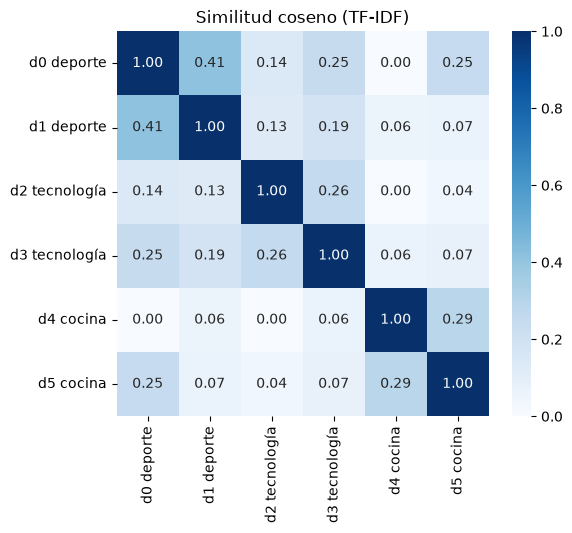

In [7]:
sim = cosine_similarity(tfidf_sk)
etiquetas = [f"d{i} {t}" for i, t in enumerate(temas)]
plt.figure(figsize=(6, 5))
sns.heatmap(sim, annot=True, fmt=".2f", cmap="Blues", xticklabels=etiquetas, yticklabels=etiquetas)
plt.title("Similitud coseno (TF-IDF)")
plt.show()

Los bloques de la diagonal muestran que los documentos del mismo tema son más similares entre sí. Nota que *d2* y *d3* comparten *computador* y *memoria*, mientras que *d0* y *d1* comparten *partido*, *gol* y *equipo*.

<a id="un-buscador-de-documentos"></a>
<h2 style="color: #007ACC;">Un buscador de documentos</h2>

Escalemos a un corpus real: **20 Newsgroups**, mensajes de foros de discusión en inglés sobre 20 temas. Usaremos cuatro categorías y quitaremos encabezados, firmas y citas para que el modelo no se apoye en metadatos.

In [8]:
categorias = ["rec.autos", "sci.space", "comp.graphics", "rec.sport.hockey"]
news = fetch_20newsgroups(subset="train", categories=categorias, remove=("headers", "footers", "quotes"),
                          random_state=SEED)
textos = [t for t in news.data]
y_news = news.target
nombres = news.target_names

print(f"Documentos: {len(textos)}")
print(pd.Series([nombres[i] for i in y_news]).value_counts())

Documentos: 2371
rec.sport.hockey    600
rec.autos           594
sci.space           593
comp.graphics       584
Name: count, dtype: int64


In [9]:
tfidf = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.5)
X_news = tfidf.fit_transform(textos)
print(f"Matriz TF-IDF: {X_news.shape[0]} documentos x {X_news.shape[1]} términos "
      f"({X_news.nnz / np.prod(X_news.shape):.2%} de celdas no nulas)")

Matriz TF-IDF: 2371 documentos x 8926 términos (0.57% de celdas no nulas)


Un **buscador** basado en espacios vectoriales trata la consulta como un documento más: la vectoriza con el mismo `TfidfVectorizer` y devuelve los documentos con mayor similitud coseno.

In [10]:
def buscar(consulta, k=5):
    q = tfidf.transform([consulta])
    sims = cosine_similarity(q, X_news).ravel()
    mejores = np.argsort(sims)[::-1][:k]
    return pd.DataFrame({
        "similitud": sims[mejores].round(3),
        "categoría": [nombres[y_news[i]] for i in mejores],
        "texto": [" ".join(textos[i].split())[:110] + "..." for i in mejores],
    })


pd.set_option("display.max_colwidth", 120)
buscar("nasa shuttle launch orbit")

,similitud,categoría,texto
0,0.374,sci.space,"Archive-name: space/schedule Last-modified: $Date: 93/04/01 14:39:23 $ SPACE SHUTTLE ANSWERS, LAUNCH SCHEDULES..."
1,0.350,sci.space,"Hello everyone, I was hoping someone could help me out. I'm writing a program for my astronautics class for as..."
2,0.302,sci.space,Archive-name: space/controversy Last-modified: $Date: 93/04/01 14:39:06 $ CONTROVERSIAL QUESTIONS These issues...
3,0.292,sci.space,"Brian Yamauchi asks: [Regarding orbital billboards...] Well, I had been collecting data for next edition of th..."
4,0.291,sci.space,"In fact, you probably want to avoid US Government anything for such a project. The pricetag is invariably too ..."


In [11]:
buscar("engine oil and brakes")

,similitud,categoría,texto
0,0.349,rec.autos,"If the tire has a leak you should fix it. Doesn't work too well if the engine is hot, its more accurate to che..."
1,0.303,rec.autos,Why crawl under the car at all? I have a machine I got for my boat that pulls the oil out under suction throug...
2,0.278,rec.autos,"My Honda Accord just hit the magic 100,000 mile mark and now all sorts of things are beginning to go bad. The ..."
3,0.276,rec.autos,"I find this method much better myself, too, although I do really hate it when the bolt finally comes loose and..."
4,0.239,rec.autos,Archive-name: rec-autos/part5 [this article is one of a pair of articles containing commonly asked automotive ...


Limitación importante: la similitud es **léxica**. Dos textos que dicen lo mismo con palabras distintas (sinónimos) no comparten ninguna dimensión, así que su similitud es cero:

In [12]:
t1, t2 = "my automobile needs repair", "the car is broken"
v1, v2 = tfidf.transform([t1, t2])
print("Términos de t1:", tfidf.inverse_transform(v1)[0])
print("Términos de t2:", tfidf.inverse_transform(v2)[0])
print(f"Similitud coseno: {cosine_similarity(v1, v2)[0, 0]:.2f}")

Términos de t1: ['automobile' 'needs' 'repair']
Términos de t2: ['broken' 'car']
Similitud coseno: 0.00


Para resolverlo necesitamos representaciones en las que *car* y *automobile* queden **cerca**. Volveremos a esto al final del cuaderno.

<a id="visualizacion-con-pca"></a>
<h2 style="color: #007ACC;">Visualización con PCA</h2>

Los vectores TF-IDF viven en un espacio de miles de dimensiones. Para visualizarlos los proyectamos a 2D.

El **Análisis de Componentes Principales** (PCA) encuentra las direcciones ortogonales de máxima varianza de los datos. Como la matriz TF-IDF es dispersa y enorme, primero aplicamos **SVD truncada** (que trabaja directamente sobre matrices dispersas; aplicada a matrices término-documento se conoce como **análisis semántico latente**, LSA) a 100 dimensiones, y luego PCA a 2.

Varianza explicada por 100 componentes de SVD: 18.8%


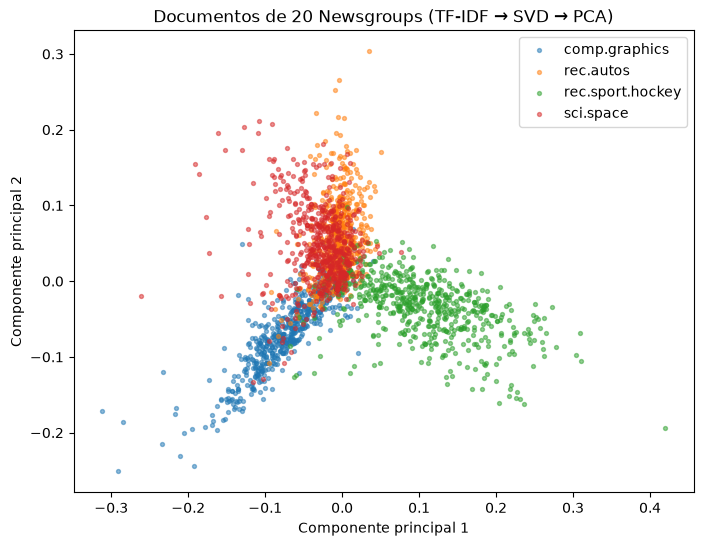

In [13]:
svd = TruncatedSVD(n_components=100, random_state=SEED)
X_lsa = svd.fit_transform(X_news)
print(f"Varianza explicada por 100 componentes de SVD: {svd.explained_variance_ratio_.sum():.1%}")

X_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_lsa)

plt.figure(figsize=(8, 6))
for i, nombre in enumerate(nombres):
    m = y_news == i
    plt.scatter(X_2d[m, 0], X_2d[m, 1], s=8, alpha=0.5, label=nombre)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Documentos de 20 Newsgroups (TF-IDF → SVD → PCA)")
plt.legend()
plt.show()

Aun sin usar las etiquetas, los documentos de cada tema tienden a agruparse en regiones distintas del plano. Las dos primeras componentes solo capturan una pequeña parte de la varianza, así que hay bastante solapamiento: en el espacio original las clases están mucho mejor separadas.

Las componentes de LSA también son interpretables: cada una es una combinación de palabras, una especie de "tópico latente".

In [14]:
terminos = tfidf.get_feature_names_out()
for i in range(5):
    comp = svd.components_[i]
    print(f"Componente {i}: {', '.join(terminos[np.argsort(comp)[::-1][:8]])}")

Componente 0: like, just, space, don, car, know, think, good
Componente 1: game, team, hockey, play, players, season, games, nhl
Componente 2: car, space, cars, just, dealer, engine, like, people
Componente 3: space, nasa, shuttle, launch, orbit, lunar, earth, moon
Componente 4: car, 10, 11, period, 12, pts, pp, 18


<a id="vectores-de-palabras-por-co-ocurrencia"></a>
<h2 style="color: #007ACC;">Vectores de palabras por co-ocurrencia</h2>

Hasta ahora hemos representado **documentos**. Para representar **palabras** aplicamos la hipótesis distribucional directamente: construimos una **matriz de co-ocurrencia** $C$ donde $C_{ij}$ cuenta cuántas veces la palabra $j$ aparece en una ventana de $k$ palabras alrededor de la palabra $i$.

Las co-ocurrencias crudas están dominadas por palabras frecuentes. Por eso se transforman con la **información mutua puntual positiva** (PPMI), que mide si dos palabras aparecen juntas **más de lo esperado por azar**:

$$\text{PMI}(w, c) = \log \frac{P(w, c)}{P(w)\,P(c)}, \qquad \text{PPMI}(w, c) = \max(\text{PMI}(w, c), 0)$$

Finalmente reducimos la dimensión con SVD para obtener vectores **densos** de unas pocas decenas de dimensiones.

In [15]:
analizador = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{2,}\b").build_analyzer()
tokens_docs = [analizador(t) for t in textos]

conteo = Counter(w for doc in tokens_docs for w in doc)
vocab_w = [w for w, c in conteo.most_common(5000)]
indice = {w: i for i, w in enumerate(vocab_w)}

VENTANA = 4
filas, cols = [], []
for doc in tokens_docs:
    ids = [indice[w] for w in doc if w in indice]
    for pos, i in enumerate(ids):
        for j in ids[max(0, pos - VENTANA):pos] + ids[pos + 1:pos + 1 + VENTANA]:
            filas.append(i)
            cols.append(j)

C = sparse.coo_matrix((np.ones(len(filas)), (filas, cols)), shape=(len(vocab_w), len(vocab_w))).tocsr()
print(f"Matriz de co-ocurrencia: {C.shape}, {C.nnz:,} pares distintos")

Matriz de co-ocurrencia: (5000, 5000), 785,570 pares distintos


In [16]:
def ppmi(C):
    C = C.toarray()
    total = C.sum()
    p_w = C.sum(axis=1, keepdims=True) / total
    p_c = C.sum(axis=0, keepdims=True) / total
    with np.errstate(divide="ignore", invalid="ignore"):
        pmi = np.log((C / total) / (p_w * p_c))
    pmi[~np.isfinite(pmi)] = 0.0
    return np.maximum(pmi, 0)


M = ppmi(C)
vectores = TruncatedSVD(n_components=100, random_state=SEED).fit_transform(M)
vectores /= np.linalg.norm(vectores, axis=1, keepdims=True)  # así el producto punto es la similitud coseno
print("Vectores de palabras:", vectores.shape)

Vectores de palabras: (5000, 100)


In [17]:
def vecinos(palabra, k=8):
    sims = vectores @ vectores[indice[palabra]]
    mejores = np.argsort(sims)[::-1][1:k + 1]
    return [f"{vocab_w[i]} ({sims[i]:.2f})" for i in mejores]


for palabra in ["car", "orbit", "hockey", "image", "engine", "goal"]:
    print(f"{palabra:<8} -> {', '.join(vecinos(palabra))}")

car      -> cars (0.87), miles (0.79), dealer (0.79), drive (0.75), ford (0.75), engine (0.75), just (0.74), buy (0.74)
orbit    -> earth (0.81), jupiter (0.75), spacecraft (0.75), hiten (0.74), moon (0.72), planet (0.72), venus (0.71), asteroid (0.71)
hockey   -> league (0.88), nhl (0.82), teams (0.81), team (0.76), canadian (0.75), players (0.75), leagues (0.73), fans (0.73)
image    -> images (0.83), display (0.82), color (0.80), manipulation (0.78), screen (0.76), processing (0.76), functions (0.76), tool (0.75)
engine   -> miles (0.76), rebuilt (0.75), car (0.75), liter (0.71), motor (0.68), cars (0.67), valve (0.66), gasoline (0.65)
goal     -> scored (0.81), shot (0.80), lead (0.78), puck (0.77), game (0.77), soderstrom (0.76), shots (0.76), swedes (0.75)


Sin ninguna supervisión, solo contando co-ocurrencias en unos pocos miles de mensajes, el modelo descubre relaciones semánticas: palabras del mismo campo quedan cerca. Visualicemos un grupo de palabras:

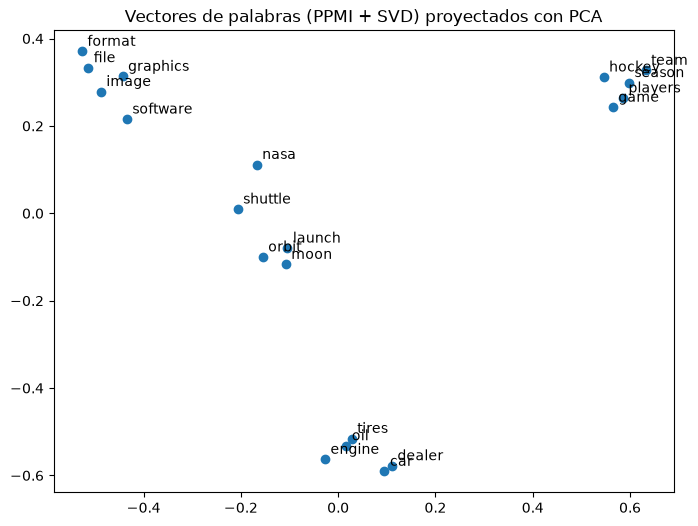

In [18]:
palabras = ["car", "engine", "oil", "tires", "dealer", "orbit", "nasa", "moon", "launch", "shuttle",
            "image", "graphics", "file", "format", "software", "hockey", "team", "game", "season", "players"]
P = PCA(n_components=2, random_state=SEED).fit_transform(vectores[[indice[w] for w in palabras]])

plt.figure(figsize=(8, 6))
plt.scatter(P[:, 0], P[:, 1], c="tab:blue")
for w, (x, y) in zip(palabras, P):
    plt.annotate(w, (x, y), xytext=(4, 4), textcoords="offset points")
plt.title("Vectores de palabras (PPMI + SVD) proyectados con PCA")
plt.show()

<a id="hacia-los-embeddings"></a>
<h2 style="color: #007ACC;">Hacia los embeddings</h2>

| Representación | Unidad | Dimensión | Densidad | Captura similitud entre sinónimos |
|----------------|--------|-----------|----------|-----------------------------------|
| Bolsa de palabras / TF-IDF | Documento | Tamaño del vocabulario (miles) | Dispersa | No |
| LSA (TF-IDF + SVD) | Documento | ~100 | Densa | Parcialmente |
| PPMI + SVD | Palabra | ~100 | Densa | Sí |
| Word2Vec, GloVe (módulo 3) | Palabra | 50–300 | Densa | Sí |
| Embeddings contextuales: BERT (módulo 4) | Palabra *en contexto* | 768+ | Densa | Sí, y distingue sentidos |

Los vectores densos de palabras permiten operaciones sorprendentes. Con buenos embeddings entrenados en corpus grandes se cumplen **analogías** del tipo:

$$\vec{\text{rey}} - \vec{\text{hombre}} + \vec{\text{mujer}} \approx \vec{\text{reina}}$$

Nuestros vectores, entrenados con pocos documentos de solo cuatro temas, no alcanzan esa calidad. En el módulo 3 aprenderemos a entrenar embeddings con redes neuronales (Word2Vec) y a usar embeddings preentrenados (GloVe) sobre corpus de miles de millones de palabras. GloVe, de hecho, se basa directamente en la matriz de co-ocurrencia que construimos aquí.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Lane, H., Howard, C. & Hapke, H. (2019). *Natural Language Processing in Action*. Manning.
- Documentación de scikit-learn: *Working With Text Data*. [scikit-learn.org](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html)
- Deerwester, S. et al. (1990). Indexing by Latent Semantic Analysis. *Journal of the American Society for Information Science*, 41(6).
- Levy, O., Goldberg, Y. & Dagan, I. (2015). Improving Distributional Similarity with Lessons Learned from Word Embeddings. *TACL*, 3.